## Question

An urn starts with one red ball and one blue ball. On each turn, draw one ball, put it back, and add one more ball of the same color.

After 100 turns, what is the probability that more than 90% of the balls are red?


## Solution

After 100 turns there are 102 balls. If $R$ is the number of red draws, then the urn has $1+R$ red balls. More than 90% red requires

$\frac{1+R}{102}>0.9,$

so $R\ge 91$.

In this urn, the number of red draws after 100 turns is equally likely to be any value from 0 to 100. One way to see this is that the probability of any particular color sequence with $r$ red draws is $\frac{r!(100-r)!}{101!}$; summing over the $\binom{100}{r}$ such sequences gives $1/101$ for each $r$.

There are 10 possible counts from 91 through 100, so

$P(R\ge 91)=\frac{10}{101}\approx 0.0990.$

Thus the probability is about 9.9%.

## Simulation


In [ ]:
import random
from collections import Counter

rng = random.Random(0)
games = 20_000
turns = 100
red_draw_counts = []

for _ in range(games):
    red = 1
    blue = 1

    for _ in range(turns):
        if rng.random() < red / (red + blue):
            red += 1
        else:
            blue += 1

    red_draw_counts.append(red - 1)

counts = Counter(red_draw_counts)
red_fraction = sum(k >= 91 for k in red_draw_counts) / games
exact_probability = 10 / 101

print(f"Simulated probability above 90% red: {red_fraction:.3f}")
print(f"Exact probability:                 {exact_probability:.3f}")
print(f"Exact probability above 90%:      {exact_probability:.1%}")

Simulated probability above 90% red: 0.101
Exact probability:                 0.099
Exact probability above 90%:      9.9%


## Visualization


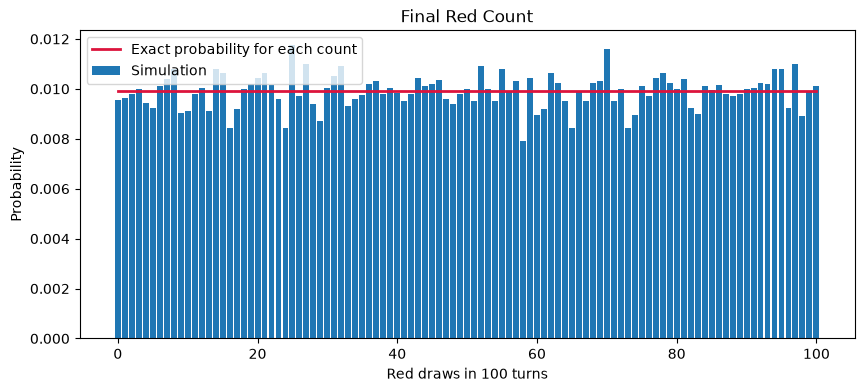

In [9]:
import matplotlib.pyplot as plt

possible_red_draws = range(turns + 1)
observed = [counts[k] / games for k in possible_red_draws]
exact = [1 / (turns + 1)] * (turns + 1)

plt.figure(figsize=(10, 4))
plt.bar(possible_red_draws, observed, width=0.85, label="Simulation")
plt.plot(possible_red_draws, exact, color="crimson", linewidth=2,
         label="Exact probability for each count")
plt.xlabel("Red draws in 100 turns")
plt.ylabel("Probability")
plt.title("Final Red Count")
plt.legend()
plt.show()